# Mini Project 02 Working Document

In [1]:
%%html
<style type="text/css">
.note {background-color: #cdf7f7; padding: 15px;}
.finding {background-color: #d8f5c4; padding: 15px;}
</style>

## Business Requirements

The business wants to predict how long an incident will take to resolve. This will help them manage and plan the workforce deployed and provide a realistic estimate to customers about when to expect the incident raised can be resolved.  

The objective of this project is to understand what the factors are that influence the length of time to resolve an incident.

A machine learning model will be built based on the historical dataset extracted from ServiceNow.


## Libaries

In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import math
import seaborn as sns
import datetime as dt

from scipy import stats
from matplotlib import pyplot as plt

%matplotlib inline

from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score


In [3]:
# this is to stop the warning messages appearing
pd.set_option('future.no_silent_downcasting', True)

## Data Dictionary

Data source: 
https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log 

Attribute information of this dataset:

1. number: incident identifier (24,918 different values);
2. incident state: eight levels controlling the incident management process transitions from opening until closing the case;
3. active: boolean attribute that shows whether the record is active or closed/canceled;
4. reassignment_count: number of times the incident has the group or the support analysts changed;
5. reopen_count: number of times the incident resolution was rejected by the caller;
6. sys_mod_count: number of incident updates until that moment;
7. made_sla: boolean attribute that shows whether the incident exceeded the target SLA;
8. caller_id: identifier of the user affected;
9. opened_by: identifier of the user who reported the incident;
10. opened_at: incident user opening date and time;
11. sys_created_by: identifier of the user who registered the incident;
12. sys_created_at: incident system creation date and time;
13. sys_updated_by: identifier of the user who updated the incident and generated the current log record;
14. sys_updated_at: incident system update date and time;
15. contact_type: categorical attribute that shows by what means the incident was reported;
16. location: identifier of the location of the place affected;
17. category: first-level description of the affected service;
18. subcategory: second-level description of the affected service (related to the first level description, i.e., to category);
19. u_symptom: description of the user perception about service availability;
20. cmdb_ci: (confirmation item) identifier used to report the affected item (not mandatory);
21. impact: description of the impact caused by the incident (values: 1-High; 2-Medium; 3-Low);
22. urgency: description of the urgency informed by the user for the incident resolution (values: 1-High; 2-Medium; 3-Low);
23. priority: calculated by the system based on 'impact' and 'urgency';
24. assignment_group: identifier of the support group in charge of the incident;
25. assigned_to: identifier of the user in charge of the incident;
26. knowledge: boolean attribute that shows whether a knowledge base document was used to resolve the incident;
27. u_priority_confirmation: boolean attribute that shows whether the priority field has been double-checked;
28. notify: categorical attribute that shows whether notifications were generated for the incident;
29. problem_id: identifier of the problem associated with the incident;
30. rfc: (request for change) identifier of the change request associated with the incident;
31. vendor: identifier of the vendor in charge of the incident;
32. caused_by: identifier of the RFC responsible by the incident;
33. close_code: identifier of the resolution of the incident;
34. resolved_by: identifier of the user who resolved the incident;
35. resolved_at: incident user resolution date and time (dependent variable);
36. closed_at: incident user close date and time (dependent variable).

## 1. Load and explore the data

### 1.1 Load Data

In [4]:
%time
df = pd.read_csv('incident_event_log.csv')

CPU times: total: 0 ns
Wall time: 3.1 μs


<div class = "finding">
    <b>Findings</b>: 
    <br>1. It does not seem too slow to read the csv file. It will be fine to explore the dataset without causing performance issues.
</div>

### 1.2 Explore Data

In [5]:
# check the shape 
_shape = df.shape
print(f"The dataset has {_shape[0]} rows and {_shape[1]} columns.")

The dataset has 141712 rows and 36 columns.


In [6]:
# view the dataset by sampling the top 5 rows, transposing the rows and columns
df.head(5).T

,0,1,2,3,4
number,INC0000045,INC0000045,INC0000045,INC0000045,INC0000047
incident_state,New,Resolved,Resolved,Closed,New
active,True,True,True,False,True
reassignment_count,0,0,0,0,0
reopen_count,0,0,0,0,0
sys_mod_count,0,2,3,4,0
made_sla,True,True,True,True,True
caller_id,Caller 2403,Caller 2403,Caller 2403,Caller 2403,Caller 2403
opened_by,Opened by 8,Opened by 8,Opened by 8,Opened by 8,Opened by 397
opened_at,29/2/2016 01:16,29/2/2016 01:16,29/2/2016 01:16,29/2/2016 01:16,29/2/2016 04:40


<div class = "finding">
    <b>Findings</b>: 
    <br>2. The top four rows have the same incident id number. This confirmed the first item of the 'Attribute Information' in the data dictionary. There are 141,712 events (the index of the rows) for 24,918 incidents (the INC number).
    <br>3. It is probably safe to assume that this dataset has been denormalised which joint multiple tables. From a quick glance of the top 5 rows, it seems that I can at least normalise the dataset into two tables, one table to record the data about incidents, the other about the changes of the incidents.
    <br>4. There are many cells with missing values which is signified with question marks. Need further investigation to decide what to do to fill the missing values.
    <br>
</div>

In [7]:
# check datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 36 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   number                   141712 non-null  object
 1   incident_state           141712 non-null  object
 2   active                   141712 non-null  bool  
 3   reassignment_count       141712 non-null  int64 
 4   reopen_count             141712 non-null  int64 
 5   sys_mod_count            141712 non-null  int64 
 6   made_sla                 141712 non-null  bool  
 7   caller_id                141712 non-null  object
 8   opened_by                141712 non-null  object
 9   opened_at                141712 non-null  object
 10  sys_created_by           141712 non-null  object
 11  sys_created_at           141712 non-null  object
 12  sys_updated_by           141712 non-null  object
 13  sys_updated_at           141712 non-null  object
 14  contact_type        

<div class = "finding">
    <b>Findings</b>: 
    <br>5. I will change these columns with boolean values to 1 (True) or 0 (False): active, made_sla, knowledge, u_priority_confirmation
    <br>6. I will change these columns with object datatype to datetime datatype: opened_at, sys_created_at, sys_updated_at, resolved_at, closed_at
</div>

In [8]:
# check missing values
df.isnull().sum()

number                     0
incident_state             0
active                     0
reassignment_count         0
reopen_count               0
sys_mod_count              0
made_sla                   0
caller_id                  0
opened_by                  0
opened_at                  0
sys_created_by             0
sys_created_at             0
sys_updated_by             0
sys_updated_at             0
contact_type               0
location                   0
category                   0
subcategory                0
u_symptom                  0
cmdb_ci                    0
impact                     0
urgency                    0
priority                   0
assignment_group           0
assigned_to                0
knowledge                  0
u_priority_confirmation    0
notify                     0
problem_id                 0
rfc                        0
vendor                     0
caused_by                  0
closed_code                0
resolved_by                0
resolved_at   

<div class = "finding">
    <b>Findings</b>: 
    <br>7. The question marks cause a problem. They make it difficult to assess how many missing values to fill in this dataset. 
</div>

In [9]:
df = df.replace({"?": None}) # remove the question marks to find out more about missing values
df.isnull().sum() # check missing values

number                          0
incident_state                  0
active                          0
reassignment_count              0
reopen_count                    0
sys_mod_count                   0
made_sla                        0
caller_id                      29
opened_by                    4835
opened_at                       0
sys_created_by              53076
sys_created_at              53076
sys_updated_by                  0
sys_updated_at                  0
contact_type                    0
location                       76
category                       78
subcategory                   111
u_symptom                   32964
cmdb_ci                    141267
impact                          0
urgency                         0
priority                        0
assignment_group            14213
assigned_to                 27496
knowledge                       0
u_priority_confirmation         0
notify                          0
problem_id                 139417
rfc           

<div class = "note">
    <b>Notes</b>: 
    <br>1. I can not fill the missing values in 'sys_created_at' with 0 as the data type is datetime and 0 has meanings. 
    <br>2. I may be able to fill the missing values in other columns which have string data.  
</div>

In [10]:
# check numbers of unique values in the columns
df.nunique()

number                     24918
incident_state                 9
active                         2
reassignment_count            28
reopen_count                   9
sys_mod_count                115
made_sla                       2
caller_id                   5244
opened_by                    207
opened_at                  19849
sys_created_by               185
sys_created_at             11552
sys_updated_by               846
sys_updated_at             50664
contact_type                   5
location                     224
category                      58
subcategory                  254
u_symptom                    525
cmdb_ci                       50
impact                         3
urgency                        3
priority                       4
assignment_group              78
assigned_to                  234
knowledge                      2
u_priority_confirmation        2
notify                         2
problem_id                   252
rfc                          181
vendor    

<div class = "finding">
    <b>Findings</b>:
    <br>8. 'caller_id' tells me that 5244 customers have requested services.
    <br>9. 'opened_by', 'assigned_to', 'assignment_group' and,'resolved_by' tells me that about 207 (opened_by) to 846 (sys_updated_by) IT staff from 78 teams were allocated to provide the support services.
    <br>10. 'resolved_at' and 'closed_at' tells me that there may be a significant gap between the resolved_at datetime and the closed_at datetime. Assuming that the resolved_at datetime were entered by the IT staff working on the incident and the closed_at datetime were generated by the system.
</div>

### 1.3 Fill in Missing Data

<div class = "note">
    <b>Notes</b>: 
    <br>3. I will explore how to fill the missing values. 
    <br>   >> Is it a viable option to fill the missing values based on the INC numbers? 
    <br>   >> For example, did some tickets only captured data at the first and last events of the incident?
</div>

In [11]:
# fill the missing values in sys_created_at

## 1. create a series of the mode of each incident
def incident(series):
    mode = pd.Series.mode(series)
    if len(mode)==0:
        return pd.NA
    elif len(mode)==1:
        return mode
    return mode[0]

incident_fillin = df.groupby(by='number')['sys_created_at'].agg(incident)

incident_fillin

number
INC0000045    29/2/2016 01:23
INC0000047    29/2/2016 04:57
INC0000057               <NA>
INC0000060    29/2/2016 06:42
INC0000062    29/2/2016 07:26
                   ...       
INC0120304               <NA>
INC0120319               <NA>
INC0120495               <NA>
INC0120835               <NA>
INC0121064               <NA>
Name: sys_created_at, Length: 24918, dtype: object

In [12]:
## 2. create a series of caller_id is null with index
sys_created_at_mask = df['sys_created_at'].isna()

sys_created_at_mask

0         False
1         False
2         False
3         False
4         False
          ...  
141707     True
141708     True
141709     True
141710     True
141711     True
Name: sys_created_at, Length: 141712, dtype: bool

In [13]:

## 3. map the title between two series and assign the caller id in the fillin series to the null values
df.loc[sys_created_at_mask, 'sys_created_at'] = df.loc[sys_created_at_mask,'number'].map(incident_fillin)

df['sys_created_at']

0         29/2/2016 01:23
1         29/2/2016 01:23
2         29/2/2016 01:23
3         29/2/2016 01:23
4         29/2/2016 04:57
               ...       
141707               <NA>
141708               <NA>
141709               <NA>
141710               <NA>
141711               <NA>
Name: sys_created_at, Length: 141712, dtype: object

In [14]:

## 4. check the dataset column 'sys_created_at' again to see if the filling worked
df[df['sys_created_at'].isnull()]

,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
13,INC0000057,New,True,0,0,0,True,Caller 4416,Opened by 8,29/2/2016 06:10,...,False,Do Not Notify,None,None,None,None,code 10,Resolved by 5,1/3/2016 02:55,6/3/2016 03:00
14,INC0000057,New,True,0,0,1,True,Caller 4416,Opened by 8,29/2/2016 06:10,...,False,Do Not Notify,None,None,None,None,code 10,Resolved by 5,1/3/2016 02:55,6/3/2016 03:00
15,INC0000057,New,True,0,0,2,True,Caller 4416,Opened by 8,29/2/2016 06:10,...,False,Do Not Notify,Problem ID 2,None,None,None,code 10,Resolved by 5,1/3/2016 02:55,6/3/2016 03:00
16,INC0000057,New,True,0,0,3,True,Caller 4416,Opened by 8,29/2/2016 06:10,...,False,Do Not Notify,Problem ID 2,None,None,None,code 10,Resolved by 5,1/3/2016 02:55,6/3/2016 03:00
17,INC0000057,New,True,0,0,4,True,Caller 4416,Opened by 8,29/2/2016 06:10,...,False,Do Not Notify,Problem ID 2,None,None,None,code 10,Resolved by 5,1/3/2016 02:55,6/3/2016 03:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141707,INC0120835,Closed,False,1,0,4,True,Caller 116,Opened by 12,16/2/2017 09:09,...,True,Do Not Notify,None,None,None,None,code 9,Resolved by 9,16/2/2017 09:53,16/2/2017 09:53
141708,INC0121064,Active,True,0,0,0,True,Caller 116,Opened by 12,16/2/2017 14:17,...,False,Do Not Notify,None,None,None,None,code 6,Resolved by 9,16/2/2017 16:38,16/2/2017 16:38
141709,INC0121064,Active,True,1,0,1,True,Caller 116,Opened by 12,16/2/2017 14:17,...,False,Do Not Notify,None,None,None,None,code 6,Resolved by 9,16/2/2017 16:38,16/2/2017 16:38
141710,INC0121064,Resolved,True,1,0,2,True,Caller 116,Opened by 12,16/2/2017 14:17,...,True,Do Not Notify,None,None,None,None,code 6,Resolved by 9,16/2/2017 16:38,16/2/2017 16:38


In [15]:
## 5. pick one incident number to understand why it didn't work
df[df['number'] == 'INC0121064'].T

,141708,141709,141710,141711
number,INC0121064,INC0121064,INC0121064,INC0121064
incident_state,Active,Active,Resolved,Closed
active,True,True,True,False
reassignment_count,0,1,1,1
reopen_count,0,0,0,0
sys_mod_count,0,1,2,3
made_sla,True,True,True,True
caller_id,Caller 116,Caller 116,Caller 116,Caller 116
opened_by,Opened by 12,Opened by 12,Opened by 12,Opened by 12
opened_at,16/2/2017 14:17,16/2/2017 14:17,16/2/2017 14:17,16/2/2017 14:17


<div class = "finding">
    <b>Findings</b>:
    <br>11. The date column 'sys_created_at' can be null from the begining to the end of an incident. It is not mandatory. 
    <br>12. Same can be said to these columns: 'sys_created_by', 'cmdb_ci', 'problem_id', 'rfc', 'vendor', 'caused_by'.
    <br>
</div>

<div class = "note">
    <b> Notes: </b>
    <br> 4. Can the reason of sys_created_at fields being empty has anything to do with other factors? Such as the types of contact, only self-service captured this data?
</div>

In [16]:
# check 'contact_type' when 'sys_created_at' is null
_df = df[df['sys_created_at'].isnull()]
_df['contact_type'].unique()

array(['Phone', 'Email', 'Self service', 'Direct opening', 'IVR'],
      dtype=object)

In [17]:
# check 'contact_type' when 'sys_created_at' is not null
_df = df[df['sys_created_at'].notnull()]
_df['contact_type'].unique()

array(['Phone', 'Email', 'Self service'], dtype=object)

<div class = "finding">
    <b>Findings</b>:
    <br>13. There is no clear separation of null and non null values in the 'sys_created_at' column based on the 'contact_type'. 
    <br>
</div>

<div class = "note">
    <b>Notes</b>: 
    <br>5. I will drop the two columns 'sys_created_by' and 'sys_created_at' because there are too many null values and I can not fill them. 
    <br>6. I will replace the values with True and False values in these qualitative columns which have too many null values:
    <br> >> u_symptom
    <br> >> cmdb_ci
    <br> >> problem_id
    <br> >> rfc
    <br> >> vendor
    <br> >> caused_by
    <br> I am interested in finding out if the non-null values in these columns have an impact on the learning model. Not so much in what the actual values are. Therefore, I'll replace the non-null values with 1 and null values with 0. 
    <br>7. I want to explore the possibility of filling missing values in 'resolved_at' column. I want to understand why there are null values in this column.
</div>

In [18]:
# drop the two columns I can not fill the missing values
df = df.drop(['sys_created_by', 'sys_created_at'], axis = 1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141712 entries, 0 to 141711
Data columns (total 34 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   number                   141712 non-null  object
 1   incident_state           141712 non-null  object
 2   active                   141712 non-null  bool  
 3   reassignment_count       141712 non-null  int64 
 4   reopen_count             141712 non-null  int64 
 5   sys_mod_count            141712 non-null  int64 
 6   made_sla                 141712 non-null  bool  
 7   caller_id                141683 non-null  object
 8   opened_by                136877 non-null  object
 9   opened_at                141712 non-null  object
 10  sys_updated_by           141712 non-null  object
 11  sys_updated_at           141712 non-null  object
 12  contact_type             141712 non-null  object
 13  location                 141636 non-null  object
 14  category            

In [19]:
# convert 6 columns with string data to boolean
col_TF = ['u_symptom','cmdb_ci','problem_id','rfc','vendor','caused_by']
df[col_TF] = df[col_TF].astype(bool)
for col in df[col_TF]:
    df[col] = df[col].astype(int)
    print(df[col].value_counts())

u_symptom
1    108748
0     32964
Name: count, dtype: int64
cmdb_ci
0    141267
1       445
Name: count, dtype: int64
problem_id
0    139417
1      2295
Name: count, dtype: int64
rfc
0    140721
1       991
Name: count, dtype: int64
vendor
0    141468
1       244
Name: count, dtype: int64
caused_by
0    141689
1        23
Name: count, dtype: int64


In [20]:
# check 'active' when 'resolved_at' is null
_df = df[df['resolved_at'].isnull()]
_df['active'].value_counts()


active
True     1583
False    1558
Name: count, dtype: int64

<div class = "finding">
    <b>Findings</b>:
    <br>14. There are 1558 rows that have null values in 'resolved_at' dates and the incidents have been marked as inactive. It's safe to assume that events with missing resolved dates are not active incidents.
    </div>

<div class = "note">
    <b>Notes</b>:
    <br>8. I will replace the null values in 'resolved_at' with the corresponding closed_at values.
    </div>

In [21]:
# replace missing resolve_at values with closed_at values
df['resolved_at'] = df['resolved_at'].fillna(df['closed_at'])


In [22]:
# check if there is null value in 'resolved_at'
df['resolved_at'].isna().sum()

np.int64(0)

<div class = "note">
    <b>Notes</b>: 
    <br>9. I will collapse the dataframe to one row per incident number. 
    <br>10. I will create a list of 5 columns to count unique values in these columns relating to staff (changing the data to numeric values):
    <br> >> opened_by
    <br> >> sys_updated_by
    <br> >> assignment_group
    <br> >> assigned_to
    <br> >> resolved_by
    <br> I am interested in finding out how many staff have worked on each incident. 
    <br>11. I will create a new DataFrame where the 'sys_mod_count' is the maximum for each incident. This maximum system modification count is the moment where there were no more changes to an incident and the incident reached at the end state. 
</div>

In [23]:
# create a new DataFrame counting how many staff worked on the incidents
list_workforce = df.groupby(by = 'number').agg(
     staff_opened=('opened_by', 'nunique'), 
     staff_updated=('sys_updated_by', 'nunique'), 
     assigned_groups=('assignment_group', 'nunique'),
     staff_assigned=('assigned_to', 'nunique'),
    staff_resolved=('resolved_by', 'nunique')
)


In [24]:
# check how many rows in the list_workforce dataframe
# this will make sure it is in the right shape with the new dataframe
list_workforce.shape

(24918, 5)

In [25]:
# create a new DataFrame only keeping the rows where the incidents were at the final state
df_temp1 = df.loc[df.groupby(by = 'number')['sys_mod_count'].idxmax()].set_index('number')

In [26]:
# check the shape of the DataFrame
# to make sure it is in a shape to merge with the list
df_temp1.shape

(24918, 33)

In [27]:
# drop the columns already been aggregated in List_workforce

df_temp1 = df_temp1.drop(['opened_by', 'sys_updated_by','assignment_group','assigned_to','resolved_by'], axis = 1)

In [28]:
# create a new DataFrame by merging two data sets created above

df2 = pd.concat([df_temp1, list_workforce], axis = 1)


In [29]:
# check the shape of the new DataFrame

df2.shape

(24918, 33)

In [30]:
# check the datatypes of the new DataFrame
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24918 entries, INC0000045 to INC0121064
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   incident_state           24918 non-null  object
 1   active                   24918 non-null  bool  
 2   reassignment_count       24918 non-null  int64 
 3   reopen_count             24918 non-null  int64 
 4   sys_mod_count            24918 non-null  int64 
 5   made_sla                 24918 non-null  bool  
 6   caller_id                24915 non-null  object
 7   opened_at                24918 non-null  object
 8   sys_updated_at           24918 non-null  object
 9   contact_type             24918 non-null  object
 10  location                 24912 non-null  object
 11  category                 24911 non-null  object
 12  subcategory              24910 non-null  object
 13  u_symptom                24918 non-null  int64 
 14  cmdb_ci                  2491

In [31]:
df2.isna().sum()

incident_state               0
active                       0
reassignment_count           0
reopen_count                 0
sys_mod_count                0
made_sla                     0
caller_id                    3
opened_at                    0
sys_updated_at               0
contact_type                 0
location                     6
category                     7
subcategory                  8
u_symptom                    0
cmdb_ci                      0
impact                       0
urgency                      0
priority                     0
knowledge                    0
u_priority_confirmation      0
notify                       0
problem_id                   0
rfc                          0
vendor                       0
caused_by                    0
closed_code                107
resolved_at                  0
closed_at                    0
staff_opened                 0
staff_updated                0
assigned_groups              0
staff_assigned               0
staff_re

<div class = "finding">
    <b> Findings: </b>
    <br>14: At this stage, I have 14 numeric variables and 19 non-numeric variables out of 33 columns.
</div>

### 1.4 Change Data

#### 1.4.1 Change boolean values to 1 and 0

In [32]:
# change the True False values of 4 columns to numeric values
col_BO = ['active','made_sla','knowledge','u_priority_confirmation']
df2[col_BO] = df2[col_BO].astype(int)
for _col in df2[col_BO]:
    print(df2[_col].value_counts())

active
0    24917
1        1
Name: count, dtype: int64
made_sla
1    15803
0     9115
Name: count, dtype: int64
knowledge
0    21367
1     3551
Name: count, dtype: int64
u_priority_confirmation
1    19143
0     5775
Name: count, dtype: int64


#### 1.4.2 Change date time objects to datetime

In [33]:
# # define the columns to change datatype from object to datetime
date_cols = ['opened_at', 'sys_updated_at','resolved_at','closed_at']

for col in date_cols:
    df2[col] = pd.to_datetime(df2[col], format = "%d/%m/%Y %H:%M")
 

In [34]:
# check the data types
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24918 entries, INC0000045 to INC0121064
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   incident_state           24918 non-null  object        
 1   active                   24918 non-null  int64         
 2   reassignment_count       24918 non-null  int64         
 3   reopen_count             24918 non-null  int64         
 4   sys_mod_count            24918 non-null  int64         
 5   made_sla                 24918 non-null  int64         
 6   caller_id                24915 non-null  object        
 7   opened_at                24918 non-null  datetime64[ns]
 8   sys_updated_at           24918 non-null  datetime64[ns]
 9   contact_type             24918 non-null  object        
 10  location                 24912 non-null  object        
 11  category                 24911 non-null  object        
 12  subcategory            

#### 1.4.3 Change 'contact_type' and 'incident_state' from Object to Numeric Values

In [35]:
# check the incident state values
df2['contact_type'].value_counts()

contact_type
Phone             24688
Self service        158
Email                59
IVR                   9
Direct opening        4
Name: count, dtype: int64

In [36]:
# get dummies from 'contact_type'
df2 = pd.get_dummies(df2, columns = ['contact_type'], dtype = float)


In [37]:
# replace 'Closed' with 0 and 'Active' with 1 (to numeric)
df2['incident_state'] = df2['incident_state'].replace({'Closed':0, 'Active':1})

# check values
df2['incident_state'].value_counts()

incident_state
0    24917
1        1
Name: count, dtype: int64

#### 1.4.4 Change 'impact' from Object to Numeric Values

In [38]:
# check the 'impact' values
df2['impact'].value_counts()

impact
2 - Medium    23746
3 - Low         751
1 - High        421
Name: count, dtype: int64

In [39]:
# replace '2-medium' with 2, '3-low' with 1, and '1-high' with 3 (to numeric values)
df2['impact'] = df2['impact'].replace({'3 - Low':1, '2 - Medium':2, '1 - High':3}).astype(int)

# check values
df2['impact'].value_counts()

impact
2    23746
1      751
3      421
Name: count, dtype: int64

#### 1.4.5 Change 'urgency' from Object to Numeric Values

In [40]:
# check the 'urgency' values
df2['urgency'].value_counts()

urgency
2 - Medium    23689
3 - Low         698
1 - High        531
Name: count, dtype: int64

In [41]:
# replace '2-medium' with 2, '3-low' with 1, and '1-high' with 3 (to numeric values)
df2['urgency'] = df2['urgency'].replace({'3 - Low':1, '2 - Medium':2, '1 - High':3}).astype(int)

# check values
df2['urgency'].value_counts()

urgency
2    23689
1      698
3      531
Name: count, dtype: int64

#### 1.4.6 Change 'priority' from Object to Numeric Values

In [42]:
# check the 'priority' values
df2['priority'].value_counts()

priority
3 - Moderate    23466
4 - Low           774
2 - High          408
1 - Critical      270
Name: count, dtype: int64

In [43]:
# replace '4-low' with 1, '3-moderate' with 2, '2-high' with 3, and '1-critical' with 4
df2['priority'] = df2['priority'].replace({'4 - Low':1, '3 - Moderate':2, '2 - High':3, '1 - Critical':4}).astype(int)

# check values
df2['priority'].value_counts()

priority
2    23466
1      774
3      408
4      270
Name: count, dtype: int64

#### 1.4.7 Change 'notify' from Object to Numeric Values

In [44]:
# check the 'notify' values
df2['notify'].value_counts()

notify
Do Not Notify    24882
Send Email          36
Name: count, dtype: int64

In [45]:
# replace the values with dummies
df2['notify'] = df2['notify'].replace({'Do Not Notify':0, 'Send Email':1}).astype(int)

### 1.5 Add Two Columns Calculating Time to Resolve and Time to Close 

In [46]:
# add a new column to calculate the time from opened to resolved of an incident

## the time is calculated as in 24 hour increments
df2['resolved_time'] = (df2['resolved_at'] - df2['opened_at']).dt.days
df2['resolved_time'].value_counts()

resolved_time
0      12082
5       1937
1       1835
2       1191
3        856
       ...  
135        1
178        1
190        1
204        1
80         1
Name: count, Length: 237, dtype: int64

In [47]:
# check the incidents which took more than 90 days to resolve
_df = df2[df2['resolved_time'] > 90]
_df.sort_values(by = 'resolved_time')

,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_at,sys_updated_at,location,...,staff_updated,assigned_groups,staff_assigned,staff_resolved,contact_type_Direct opening,contact_type_Email,contact_type_IVR,contact_type_Phone,contact_type_Self service,resolved_time
number,,,,,,,,,,,,,,,,,,,,,
INC0018250,0,0,3,0,34,0,Caller 5113,2016-04-12 14:54:00,2016-07-18 15:00:00,Location 204,...,4,3,2,1,0.0,0.0,0.0,1.0,0.0,91
INC0009673,0,0,4,0,38,0,Caller 1717,2016-03-21 16:57:00,2016-06-26 11:00:00,Location 111,...,3,2,2,1,0.0,0.0,0.0,1.0,0.0,91
INC0018318,0,0,3,0,38,0,Caller 4175,2016-04-12 16:27:00,2016-07-18 15:00:00,Location 204,...,7,3,2,1,0.0,0.0,0.0,1.0,0.0,91
INC0018164,0,0,1,0,32,0,Caller 2410,2016-04-12 13:31:00,2016-07-18 12:00:00,Location 204,...,3,2,1,1,0.0,0.0,0.0,1.0,0.0,91
INC0010920,0,0,0,0,35,0,Caller 3038,2016-03-24 09:59:00,2017-01-10 01:00:00,Location 204,...,3,1,1,1,0.0,0.0,0.0,1.0,0.0,91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
INC0001984,0,0,1,0,87,0,Caller 3479,2016-03-03 14:47:00,2017-01-07 09:00:00,Location 143,...,4,2,2,1,0.0,0.0,0.0,1.0,0.0,304
INC0001978,0,0,1,0,88,0,Caller 4180,2016-03-03 14:42:00,2017-01-07 09:00:00,Location 143,...,4,2,2,1,0.0,0.0,0.0,1.0,0.0,304
INC0007343,0,0,1,0,114,0,Caller 5317,2016-03-15 14:23:00,2017-02-08 18:07:00,Location 161,...,5,2,1,1,0.0,0.0,0.0,1.0,0.0,325


In [48]:
# add a new column to calculate the time from opened to closed of an incident

## the time is calculated as in 24 hour increments
df2['closed_time'] = (df2['closed_at'] - df2['opened_at']).dt.days
df2['closed_time'].value_counts()

closed_time
5      11986
6       1585
7       1077
8        878
10       850
       ...  
142        1
140        1
291        1
195        1
85         1
Name: count, Length: 245, dtype: int64

### 1.6 Statistics Summary

In [49]:
df2.describe().T

,count,mean,min,25%,50%,75%,max,std
active,24918.0,0.00004,0.0,0.0,0.0,0.0,1.0,0.006335
reassignment_count,24918.0,0.939642,0.0,0.0,0.0,1.0,27.0,1.572035
reopen_count,24918.0,0.013284,0.0,0.0,0.0,0.0,8.0,0.148922
sys_mod_count,24918.0,6.684606,1.0,2.0,4.0,8.0,129.0,8.549914
made_sla,24918.0,0.6342,0.0,0.0,1.0,1.0,1.0,0.481663
opened_at,24918,2016-04-15 16:17:42.879845888,2016-02-29 01:16:00,2016-03-21 14:59:00,2016-04-12 15:27:00,2016-05-05 14:48:45,2017-02-16 14:17:00,NaN
sys_updated_at,24918,2016-04-28 19:37:07.534312192,2016-02-29 09:27:00,2016-04-02 15:59:00,2016-04-23 11:07:00,2016-05-16 15:07:00,2017-02-18 15:00:00,NaN
u_symptom,24918.0,0.765671,0.0,1.0,1.0,1.0,1.0,0.423587
cmdb_ci,24918.0,0.002167,0.0,0.0,0.0,0.0,1.0,0.046503
impact,24918.0,1.986757,1.0,2.0,2.0,2.0,3.0,0.216473


<div class = "finding">
    <b>Findings</b>:
    <br>15. Things I am interested in:
    <br>   1) 75% incidents have been reassigned once; the maximum reassignment count is 27 times.
    <br>   2) There is no information about the distribution of reopened incidents; the maximum reopened count is 8.
    <br>   3) The earliest incident was opened on 2016 Feb 29 and 2017 Feb 16 received most incident requests.
    <br>   4) The latest date of resolved incident in this dataset is 2017 Feb 17.
    <br>   5) The latest date of closed incident in this dataset is 2017 Feb 18.
    <br>   6) 75% of the incidents were updated by 4 staff; the highest number of staff updating an incident was 18.
    <br>   7) 75% of the incidents were reassigned to 2 different groups; the highest number of group reassignment of an incident was 8.
    <br>   8) 75% of the incidents were resolved in 6 days; the longest period to resolve an incident was 336 days.
    <br>   9) 75% of the incidents were closed in 13 days; the longest period to close an incident was 341 days.
    </div>

### 1.7 Explore Data Visually 

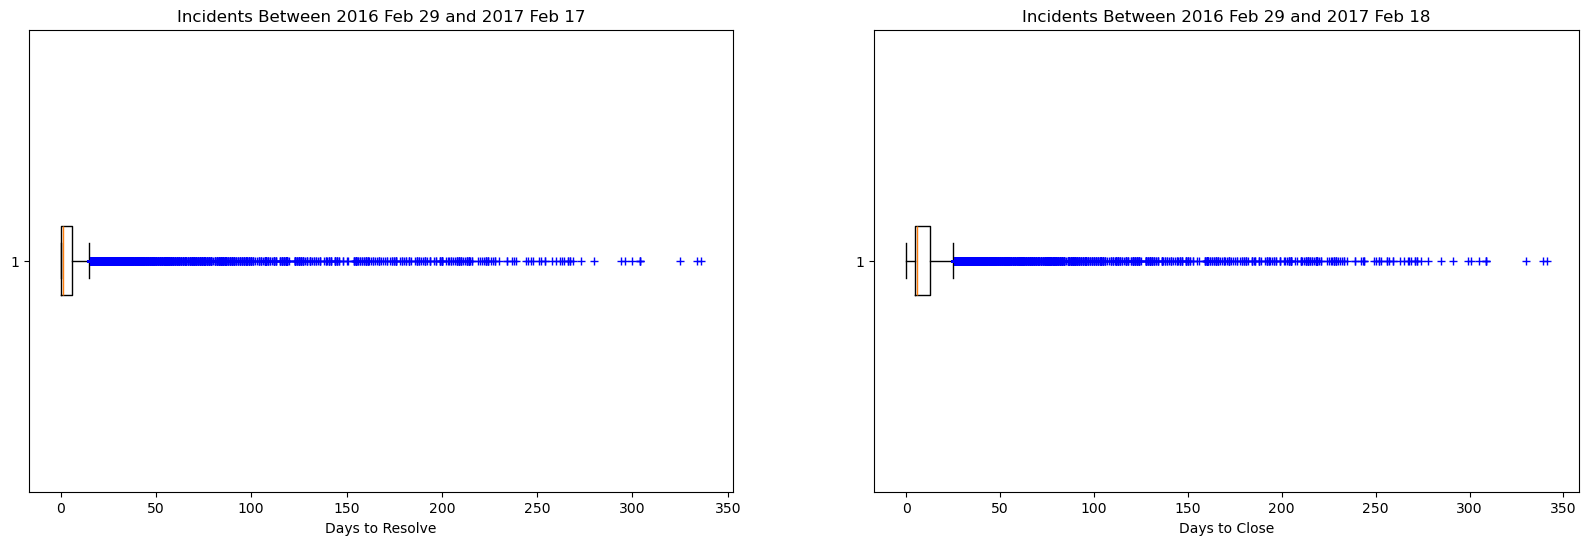

In [50]:
# view the distribution of resloved_time and closed_time

plt.figure(figsize = (20, 6))

plt.subplot(121)
ax = plt.gca()
ax.boxplot(df2['resolved_time'], orientation = 'horizontal',sym='b+')
plt.xlabel('Days to Resolve')
plt.title('Incidents Between 2016 Feb 29 and 2017 Feb 17')
plt.axis('tight')

plt.subplot(122)
ax = plt.gca()
ax.boxplot(df2['closed_time'], orientation = 'horizontal', sym='b+')
plt.xlabel('Days to Close')
plt.title('Incidents Between 2016 Feb 29 and 2017 Feb 18')
plt.axis('tight')

plt.show()

<div class = "finding">
    <b> Findings: </b>
    <br>16: Most incidents were resolved and closed under 30 days. There were a lot of outliers.
</div>

<Axes: >

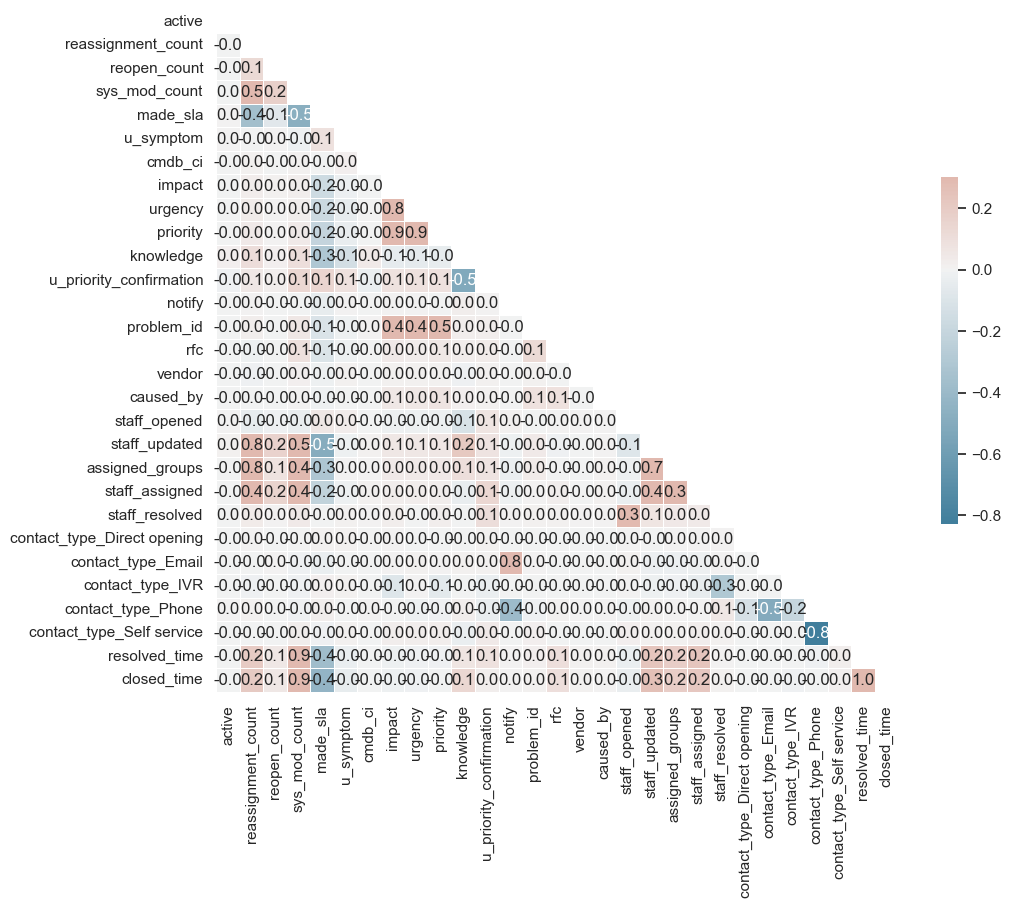

In [51]:
# create a correlation heatmap
sns.set_theme(style = 'white')

# Compute the correlation matrix
corr = df2.corr(numeric_only = True)

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0, annot = True, fmt = '.1f',
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

<div class = "finding">
    <b> Findings: </b>
    <ul>17. There are a few variables have almost no correlation with any other variables. They are 'active', 'cmdb_ci', and 'vendor'.</ul>
    <ul>18. There are a few variables have very strong correlation with other variables. They are:
    <li>'impact', 'urgency', and 'priority'</li>
    <li> 'staff_updated', 'assigned_groups', and 'reassignment_count'</li>
    <li> resolved_time', and 'closed_time'</li>
    </ul>
</div>

<div class = "note">
    <b> Notes: </b>
    <br>12. Re Finding #17, these variables have no influence on predicting any other variables. I will drop these three variables.
    <br>13. Re Finding #18, these variables are correlated to one another. I will keep only one of each three groups and drop the others.
    <br>14. Re Note #13, I will keep 'priority', 'reassignment_count', and 'resolved_time'.
</div>

In [52]:
# drop 8 columns per Notes 12 and 14
df2 = df2.drop(['active', 
                'cmdb_ci',
                'vendor',
                'impact',
                'urgency',
                'staff_updated',
                'assigned_groups',
                'closed_time'], axis = 1)
df2.shape

(24918, 31)

## 2. Build a Model to Predict When an Incident Will Be Resolved

<div class = "note">
    <b>Notes</b>: 
    <ul>15. I will build a linear regression model to predict how many days an incident may take to resolve.</ul>
    <ul>16. I will drop these non-numeric columns as they are not good predictors for resolve time.
        <li> 'incident_state' is a qualitative variable. In this dataset, all incidents were closed.</li>
        <li> 'caller_id' is a qualitative variable with 5000+ unique values. This dataset does not have enough data to analyse and predict caller characteristic and incident resolve time.</li>
        <li> 'location' is a qualitative variable with 224+ unique values. Same reason as 'caller_id'.</li>
        <li>  'category' and 'subcategory' are qualitative variables with many unique values. </li>
        <li> 'closed_code' is a qualitative variable which was not entered into the system before an incident was closed. It is not a good predictor for resolve time.</li>
        <li> 'notify' is a qualitative variable which was not entered into the system before an incident was closed. It is not a good predictor for resolve time.</li>
        <li> 5 contact_type are qualitative variables which only have correlation with 'notify'.</li>
    </ul>
    <ul>17. I will drop the datetime columns as:
        <li> the resolve time of incidents will not be influenced by increase in the opened_at, resolved_at, or closed_at  datetime values</li>
        <li> the sys_updated_at datetime value is not a quantitative predictor of the resolve time. It is highly correlated to the sys_mod_count and it can be substituted with less values. </li>
    </ul>
</div>

In [53]:
# check df2 
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24918 entries, INC0000045 to INC0121064
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   incident_state               24918 non-null  object        
 1   reassignment_count           24918 non-null  int64         
 2   reopen_count                 24918 non-null  int64         
 3   sys_mod_count                24918 non-null  int64         
 4   made_sla                     24918 non-null  int64         
 5   caller_id                    24915 non-null  object        
 6   opened_at                    24918 non-null  datetime64[ns]
 7   sys_updated_at               24918 non-null  datetime64[ns]
 8   location                     24912 non-null  object        
 9   category                     24911 non-null  object        
 10  subcategory                  24910 non-null  object        
 11  u_symptom                    249

In [54]:
# drop 7 columns per Notes 16 and 17
df2 = df2.drop(['incident_state',
                'caller_id',
                'location',
                'category',
                'subcategory',
                'closed_code',
                'contact_type_Direct opening',
                'contact_type_Email',
                'contact_type_IVR',
                'contact_type_Phone',
                'contact_type_Self service',
                'notify',
                'opened_at',
                'resolved_at',
                'closed_at',
                'sys_updated_at'
                ], axis = 1)

In [55]:
# check df3 shape
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24918 entries, INC0000045 to INC0121064
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   reassignment_count       24918 non-null  int64
 1   reopen_count             24918 non-null  int64
 2   sys_mod_count            24918 non-null  int64
 3   made_sla                 24918 non-null  int64
 4   u_symptom                24918 non-null  int64
 5   priority                 24918 non-null  int64
 6   knowledge                24918 non-null  int64
 7   u_priority_confirmation  24918 non-null  int64
 8   problem_id               24918 non-null  int64
 9   rfc                      24918 non-null  int64
 10  caused_by                24918 non-null  int64
 11  staff_opened             24918 non-null  int64
 12  staff_assigned           24918 non-null  int64
 13  staff_resolved           24918 non-null  int64
 14  resolved_time            24918 non-null  int6

### 2.1 Set Target

In [56]:
# set resolved_at as the target variable
y = df2['resolved_time']

### 2.2 Model with One Predictor - Model 1

In [57]:
# check correlation between the potential predictors and the target variable
df2.corr()['resolved_time'].sort_values()

made_sla                  -0.379155
u_symptom                 -0.032166
staff_opened              -0.027636
priority                  -0.008566
staff_resolved             0.001896
caused_by                  0.005389
problem_id                 0.016610
reopen_count               0.053139
knowledge                  0.065670
u_priority_confirmation    0.085176
rfc                        0.099041
reassignment_count         0.202508
staff_assigned             0.237013
sys_mod_count              0.882992
resolved_time              1.000000
Name: resolved_time, dtype: float64

<div class = "finding">
    <b>Findings</b>:
    <br>19. There is one feature 'sys_mod_count' which had a strong correlation with the length of time to resolve an incident.
    </div>

#### 2.2.1 Set Predictor

In [58]:
# choose 'sys_mod_count' which is most strongly correlated with 'resolve_time'
X1 = df2[['sys_mod_count']]

#### 2.2.2 Create a Linear Regression Model

In [59]:
# train-test split

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y, test_size = 0.2, random_state = 42)

In [60]:
# create a model for linear regression
lin1 = LinearRegression()

# fit model on training data
lin1.fit(X1_train, y1_train)

# calculate the score (R^2) for training data
score1_train = lin1.score(X1_train, y1_train)

print(f"The score for training data is {score1_train:.2f}.")

# calculate the score (R^2) for test data
score1_test = lin1.score(X1_test, y1_test)

print(f"The score for testing data is {score1_test:.2f}.")

The score for training data is 0.77.
The score for testing data is 0.81.


<div class = "finding">
    <b>Findings</b>:
    <br>20. The score for the strongest variable improved slightly on the testing data.
    </div>

In [61]:
# find coefficient

lin1_coef_df = pd.DataFrame({'feature': X1.columns, 'coefficient': lin1.coef_, 'intercept':lin1.intercept_})
lin1_coef_df

,feature,coefficient,intercept
0,sys_mod_count,2.191099,-7.567829


<div class = "finding">
    <b>Findings</b>:
    <br>21. Everytime an incident is updated (sys_mod_count increases by 1), the days to resolve an incident increases by 2 days.
    </div>

#### 2.2.3 Cross Validation of the Model 1

In [62]:
# set up 5-fold cross validation

k_fold1 = KFold(5, shuffle = True)
train1_scores = []
train1_rmse = []
test1_scores = []
test1_rmse = []

In [63]:
# set up for-loop to fill in the train and test scores and rmse in the 5-fold cross validation

for k, (train, test) in enumerate(k_fold1.split(X1)):
    # train-test splits
    X1_train2 = X1.iloc[train, ]
    y1_train2 = y.iloc[train, ]
    X1_test2 = X1.iloc[test, ]
    y1_test2 = y.iloc[test, ]

    # fit model with training set
    lin1.fit(X1_train2, y1_train2)

    # make predictions with training and test sets
    train2_preds = lin1.predict(X1_train2)
    test2_preds = lin1.predict(X1_test2)

    # score R^2 and rmse on training and set sets and store in the lists
    train1_scores.append(lin1.score(X1_train2, y1_train2))
    train1_rmse.append(root_mean_squared_error(y1_train2, train2_preds))
    test1_scores.append(lin1.score(X1_test2, y1_test2))
    test1_rmse.append(root_mean_squared_error(y1_test2, test2_preds))

# create a DataFrame to display R^2 and rmse

kfold_cv1 = pd.DataFrame({'Training R2': train1_scores,
                           'Test R2': test1_scores,
                           'Training RMSE': train1_rmse,
                           'Test RMSE': test1_rmse},
                         index = [1, 2, 3, 4, 5])
kfold_cv1

,Training R2,Test R2,Training RMSE,Test RMSE
1,0.786157,0.757102,9.790379,11.208882
2,0.770687,0.814702,10.270000,9.337722
3,0.778106,0.786226,10.186222,9.695954
4,0.784959,0.754091,10.119263,9.985803
5,0.778624,0.783614,10.073189,10.157854


In [64]:
# find out the statistics summary of the R^2 and rmse
kfold_cv1.describe()

,Training R2,Test R2,Training RMSE,Test RMSE
count,5.000000,5.000000,5.000000,5.000000
mean,0.779707,0.779147,10.087810,10.077243
std,0.006211,0.024739,0.182035,0.704936
min,0.770687,0.754091,9.790379,9.337722
25%,0.778106,0.757102,10.073189,9.695954
50%,0.778624,0.783614,10.119263,9.985803
75%,0.784959,0.786226,10.186222,10.157854
max,0.786157,0.814702,10.270000,11.208882


<div class = "finding">
    <b>Findings</b>:
    <br>22. On average, my model 1 can explain 78% of the variance in resolved time of incidents.
    <br>23. This model 1's predictions of the time to resolve an incident are, on average, off by 10 days. Note that the mean of resolved_time in the initial statistic summary of the dataset is 7 days.
    </div>

### 2.3 Multiple Linear Regression Model - Model 2

#### 2.3.1 Set Predictors

In [65]:
# take all columns except target as predictor variables
predictor_variables = [col for col in df2.columns if col != 'resolved_time']

# define the predictors X
X2 = pd.DataFrame(df2, columns = predictor_variables)

In [66]:
# check X
X2

,reassignment_count,reopen_count,sys_mod_count,made_sla,u_symptom,priority,knowledge,u_priority_confirmation,problem_id,rfc,caused_by,staff_opened,staff_assigned,staff_resolved
number,,,,,,,,,,,,,,
INC0000045,0,0,4,1,1,2,1,0,0,0,0,1,0,1
INC0000047,1,0,8,1,1,2,1,0,0,0,0,1,2,1
INC0000057,0,0,6,1,1,2,1,0,1,0,0,1,1,1
INC0000060,0,0,3,1,1,2,1,0,0,0,0,1,1,1
INC0000062,1,0,7,0,1,3,1,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
INC0120304,0,0,2,1,1,2,0,1,0,0,0,1,1,1
INC0120319,0,0,1,1,1,1,0,0,0,0,0,1,0,0
INC0120495,1,0,5,1,1,2,0,0,0,0,0,1,2,0


#### 2.3.2 Create a Linear Regression Model

In [67]:
# create training and tet subsets

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size = 0.2, random_state = 42)

In [68]:
# flag intermediate output or not

show_steps = False
# True for testing/debugging False for final output only

In [69]:
%time
# start with no predictors, an empty container
included = []

# list to keep track of features, R^2, and adjusted R^2 starting with 0
best = {'feature': '', 'r2': 0, 'a_r2':0}

r2_list = [] # prepare for plotting a chart
adjusted_r2_list = [] # prepare for plotting a chart

# create a model
lin2 = LinearRegression()

# get the number of cases in the test data
n_cases = X2_test.shape[0]

while True:
    changed = False

    if show_steps:
        print('')

    # features to be evaluated
    to_be_evaluated = list(set(X2.columns) - set(included))

    if show_steps:
        print(f"Start: Feature to be evaluated = {', '.join(to_be_evaluated)}")

    for new_feature in to_be_evaluated:
        if show_steps:
            print(f"Step1: Add {new_feature}")
            print(f"Step2: Try features combo = {', '.join(included + [new_feature])}")

        # fit the model with training set
        lin2_fit = lin2.fit(X2_train[included + [new_feature]], y2_train)
        # calculate the score R^2
        lin2_r2 = lin2_fit.score(X2_test[included + [new_feature]], y2_test)
        # calculate the numbers of predictors used in the model
        n_feature = len(included)+1
        # calculate the adjusted R^2
        lin2_adj_r2 = 1 - ( ( (1 - lin2_r2) * (n_cases - 1) ) / (n_cases - n_feature - 1) )

        if show_steps:
            print(f"Step2: Compare scores: This Run R2 = {lin2_r2:.3f} and AdjR2 = {lin2_adj_r2:.3f} vs Current Best {best['r2']:.3f} and {best['a_r2']:.3f}")

        # when model improves
        if lin2_adj_r2 > best['a_r2']:
            best = {'feature': new_feature, 'r2': lin2_r2, 'a_r2': lin2_adj_r2}
            changed = True
            if show_steps:
                print(f"New Best!   : Feature = {best['feature']}; R^2 = {best['r2']:.3f}; Adjusted R^2 = {best['a_r2']:.3f}")
    
    r2_list.append(best['r2'])
    adjusted_r2_list.append(best['a_r2'])
    
    if changed:
        included.append(best['feature'])
        to_be_evaluated = list(set(to_be_evaluated) - set(best['feature']))
        
        print(f"Added feature {best['feature']} with R^2 = {best['r2']:.5f} and adjusted R^2 = {best['a_r2']:.5f}")

    else:
        print('-'*50)
        break

# final output, the best feature combo
print('')
print(f"Selected {len(included)} features:")
print(', '.join(included))

CPU times: total: 0 ns
Wall time: 2.86 μs
Added feature sys_mod_count with R^2 = 0.80977 and adjusted R^2 = 0.80973
Added feature reassignment_count with R^2 = 0.88039 and adjusted R^2 = 0.88034
Added feature reopen_count with R^2 = 0.88800 and adjusted R^2 = 0.88794
Added feature u_priority_confirmation with R^2 = 0.88996 and adjusted R^2 = 0.88987
Added feature staff_assigned with R^2 = 0.89132 and adjusted R^2 = 0.89121
Added feature knowledge with R^2 = 0.89278 and adjusted R^2 = 0.89265
Added feature priority with R^2 = 0.89397 and adjusted R^2 = 0.89382
Added feature staff_resolved with R^2 = 0.89423 and adjusted R^2 = 0.89406
Added feature u_symptom with R^2 = 0.89447 and adjusted R^2 = 0.89428
--------------------------------------------------

Selected 9 features:
sys_mod_count, reassignment_count, reopen_count, u_priority_confirmation, staff_assigned, knowledge, priority, staff_resolved, u_symptom


<div class = "finding">
    <b>Findings</b>:
    <br>24. The most increase in adjusted R2 was after adding the 2nd feature reassignment_count. After that addition, the increase of adjusted R2 was smaller with each addition.
</div>

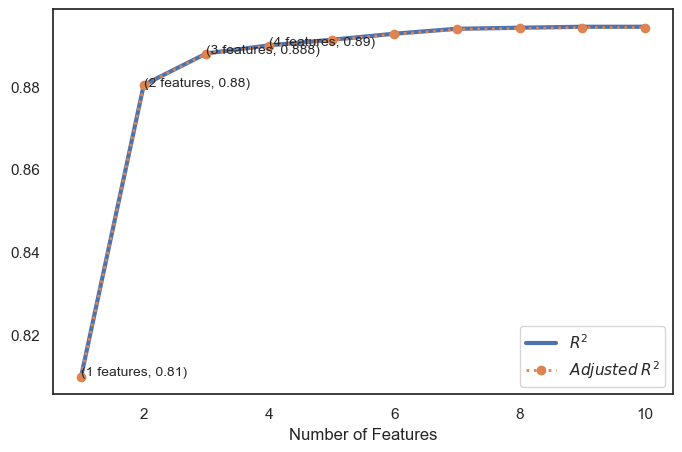

In [70]:
# chart R^2 and adjusted R^2

_range = range(1, len(r2_list)+1)
_y = np.round(adjusted_r2_list, 3)

# define chart size
plt.figure(figsize = (8, 5))
# plot each metric
plt.plot(_range, r2_list, label = '$R^2$', linewidth = 3)
plt.plot(_range, adjusted_r2_list, label = '$Adjusted \: R^2$', linewidth = 2, ls = 'dotted', marker = 'o')
for xy in zip(_range[:4], _y[:4]):
    plt.annotate('(%s features, %s)' % xy, xy = xy, textcoords = 'data', fontsize = 10)

plt.xlabel('Number of Features')
plt.legend(loc='lower right')


plt.show()


#### 2.3.3 Evaluation of Model 2's R2 and RMSE

In [71]:
# set the predictors 
X3 = pd.DataFrame(df2, columns = included)


In [72]:
# split train-test sets
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y, test_size = 0.2, random_state = 42)

In [73]:
# check R2 and rmse of Model 2

# create a model
lin3 = LinearRegression()

# use the same model set up as lin2 and fit with X3 and y3 training set
lin3.fit(X3_train, y3_train)

# test the model with test set
lin3_r2 = lin3.score(X3_test, y3_test)

# calculate predictions with test set
test3_preds = lin3.predict(X3_test)

# calculate rmse with test set
lin3_rmse = root_mean_squared_error(y3_test, test3_preds)

print('-'*50)
print(f"Model 2's score R2 is {lin3_r2:.3f}.")
print(f"Model 2's rmse is {lin3_rmse:.3f}.")

--------------------------------------------------
Model 2's score R2 is 0.894.
Model 2's rmse is 7.635.


<div class = "finding">
    <b>Findings</b>:
    <br>21. My model 2 can explain 89% of the variance in resolved time of incidents compared with 78% in model 1.
    <br>22. My model 2's predictions of the time to resolve an incident are off by 7.6 days compared with 10 days in model 1. 
    </div>

#### 2.3.4 Regularisation - Using Lasso

##### 2.3.4.1 Without Regularisation

In [74]:
# check coefficients of Model 2 with 15 features

m2_coef_metric = pd.DataFrame(data = {'feature': X3.columns, 'coef': lin3.coef_}).sort_values(by = 'coef')
m2_coef_metric

,feature,coef
2,reopen_count,-12.621632
7,staff_resolved,-7.274177
1,reassignment_count,-3.770124
3,u_priority_confirmation,-2.882605
5,knowledge,-2.754081
6,priority,-2.369170
4,staff_assigned,-1.684677
8,u_symptom,-0.957472
0,sys_mod_count,2.645453


In [75]:
# check unique values of each feature
_reopen = df2['reopen_count'].value_counts()
print(_reopen)

reopen_count
0    24643
1      245
2       19
4        4
3        4
6        2
8        1
Name: count, dtype: int64


In [76]:
df2[df2['reopen_count'] == 8].T

number,INC0019396
reassignment_count,10
reopen_count,8
sys_mod_count,68
made_sla,0
u_symptom,0
priority,2
knowledge,0
u_priority_confirmation,1
problem_id,0
rfc,0


In [77]:
# check unique values of each feature
_reopen = df2['staff_resolved'].value_counts()
print(_reopen)

staff_resolved
1    24819
0       99
Name: count, dtype: int64


In [78]:
# check unique values of each feature
_reopen = df2['reassignment_count'].value_counts()
print(_reopen)

reassignment_count
0     13549
1      6238
2      2283
3      1234
4       695
5       381
6       183
7       143
8        70
9        52
10       31
11       18
12       17
13        7
14        5
15        3
20        3
18        2
16        1
17        1
27        1
22        1
Name: count, dtype: int64


In [79]:
# check unique values of each feature
_reopen = df2['u_priority_confirmation'].value_counts() #boolean if the priority field has been double-checked
print(_reopen)

u_priority_confirmation
1    19143
0     5775
Name: count, dtype: int64


In [80]:
# check unique values of each feature
_reopen = df2['knowledge'].value_counts() #boolean if a knowledge based doc was used to resolve the incident
print(_reopen)

knowledge
0    21367
1     3551
Name: count, dtype: int64


In [81]:
# check unique values of each feature
_reopen = df2['priority'].value_counts() 
print(_reopen)

priority
2    23466
1      774
3      408
4      270
Name: count, dtype: int64


In [82]:
# check unique values of each feature
_reopen = df2['staff_assigned'].value_counts() 
print(_reopen)

staff_assigned
1    21402
2     2429
0      658
3      342
4       80
5        6
6        1
Name: count, dtype: int64


In [83]:
# check unique values of each feature
_reopen = df2['u_symptom'].value_counts() 
print(_reopen)

u_symptom
1    19079
0     5839
Name: count, dtype: int64


In [84]:
# create a function to produce coefficient plots
def view_coeff(X, model, title):
    model_coefs = pd.DataFrame({'variable': X.columns,
                                'coef': model.coef_,
                                'abs_coef': np.abs(model.coef_)})
    model_coefs.sort_values('abs_coef', inplace=True, ascending=False)
    ax = sns.barplot(x="variable", y="coef", data=model_coefs)
    plt.xticks(rotation = 60, ha = 'right')
    plt.title(title)
    plt.show()

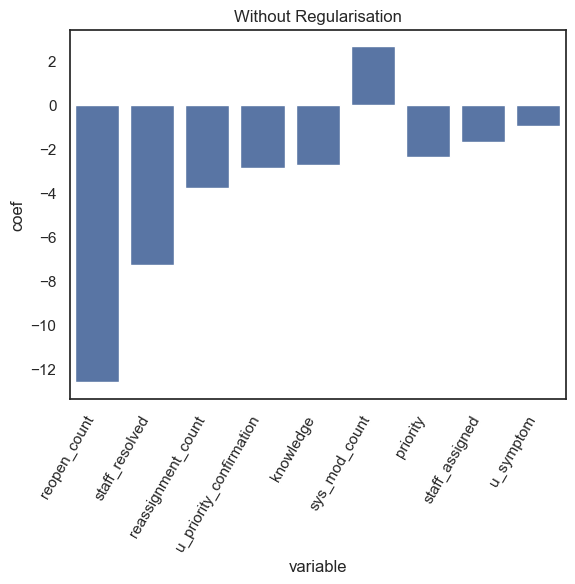

In [85]:
# plot coefficients of Model 2 without regularisation
view_coeff(X3, lin3, 'Without Regularisation')

##### 2.3.4.2 Calculate Lasso Regression Model

In [86]:
%time
# create a model object
lassomodel = Lasso()

# initialise lists for coefficients and errors
lasso_coefs = []
lasso_errors = []

# create a range of alphas 
lasso_alphas = np.logspace(-6, 6, 200)

# train the model with different regularisation alphas
for i in lasso_alphas:
    lassomodel.set_params(alpha = i)
    lassomodel.fit(X3, y)
    lasso_coefs.append(lassomodel.coef_)
    lasso_errors.append(mean_squared_error(lassomodel.coef_, lin3.coef_))



CPU times: total: 0 ns
Wall time: 2.38 μs


In [87]:
# create a DataFrame to view the lasso coefficients
lasso_coef_df = pd.DataFrame(data = lasso_coefs, columns = X3.columns)
lasso_coef_df

,sys_mod_count,reassignment_count,reopen_count,u_priority_confirmation,staff_assigned,knowledge,priority,staff_resolved,u_symptom
0,2.674401,-3.828105,-12.554860,-2.977165,-1.842646,-2.842416,-2.479113,-7.197369,-0.940818
1,2.674401,-3.828105,-12.554853,-2.977164,-1.842646,-2.842414,-2.479111,-7.197333,-0.940817
2,2.674401,-3.828105,-12.554845,-2.977163,-1.842645,-2.842411,-2.479109,-7.197290,-0.940816
3,2.674401,-3.828105,-12.554836,-2.977161,-1.842644,-2.842408,-2.479107,-7.197242,-0.940814
4,2.674401,-3.828106,-12.554826,-2.977160,-1.842643,-2.842404,-2.479105,-7.197186,-0.940813
...,...,...,...,...,...,...,...,...,...
195,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000
196,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000
197,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000
198,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,0.000000,-0.000000


##### 2.3.4.3 Visualise Coefficients of Lasso Model

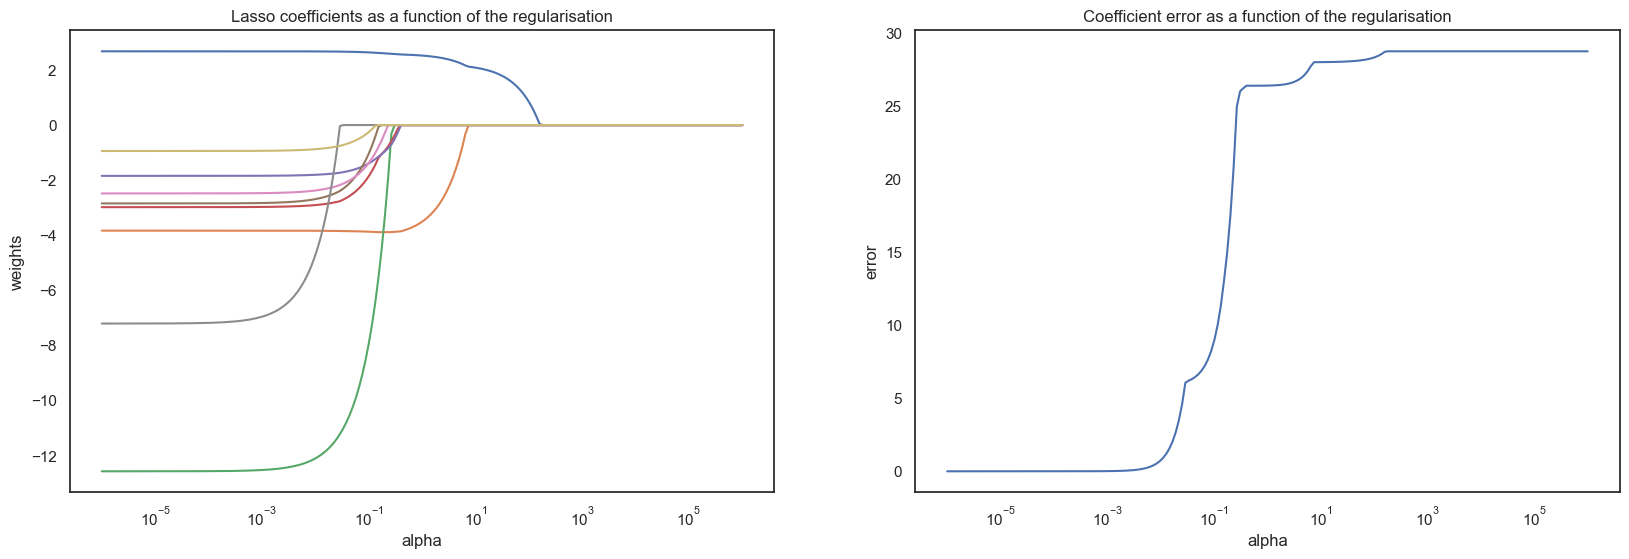

In [88]:
# Display results
plt.figure(figsize = (20, 6))

plt.subplot(121)
ax = plt.gca()
ax.plot(lasso_alphas, lasso_coefs)
ax.set_xscale('log')
plt.xlabel('alpha')
plt.ylabel('weights')
plt.title('Lasso coefficients as a function of the regularisation')
plt.axis('tight')

plt.subplot(122)
ax = plt.gca()
ax.plot(lasso_alphas, lasso_errors)
ax.set_xscale('log')
plt.xlabel('alpha')
plt.ylabel('error')
plt.title('Coefficient error as a function of the regularisation')
plt.axis('tight')

plt.show()

##### 2.3.4.4 Find an Optimal Value for Lasso Regression Alpha

In [89]:
# set up LassoCV model 
optimal_lasso = LassoCV(alphas = lasso_alphas, cv = 10)


# fit the Lasso Regression model with X3 and y
optimal_lasso.fit(X3, y)

# calculate score
lasso_score = optimal_lasso.score(X3, y)

# find the optimal Lasso Regression Alpha
optimal_alpha = optimal_lasso.alpha_

print('-'*100)
print(f"Model 3's score R2 with Lasso Regularisation is {lasso_score:.3f}.")
print(f"The optimal Lasso regularisation strength for Model 2 is {optimal_alpha:.9f}.")
print('-'*100)

----------------------------------------------------------------------------------------------------
Model 3's score R2 with Lasso Regularisation is 0.862.
The optimal Lasso regularisation strength for Model 2 is 0.000001000.
----------------------------------------------------------------------------------------------------


##### 2.3.4.5 With Regularisation

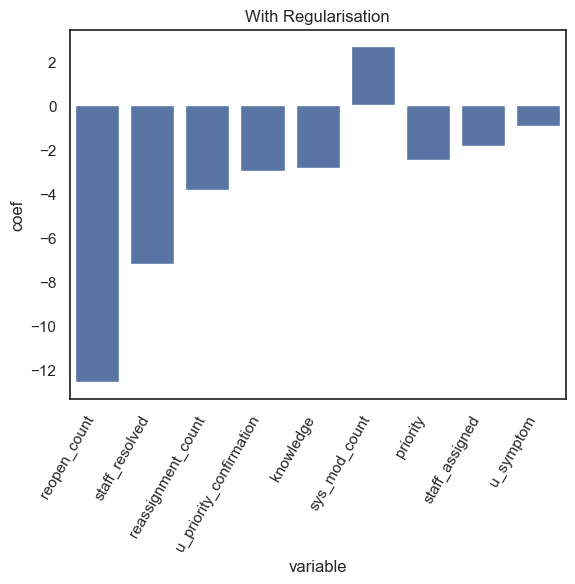

In [90]:
view_coeff(X3, optimal_lasso, 'With Regularisation')